# Inlämningsuppgift: Del 2 - Adversarial input attack

Rasmus Eliasson \
rael23@student.bth.se

Oskar Flodin \
osfl22@student.bth.se

# Instruktioner

Ändra notebookens platshållare så som era namn- och mailuppgifter samt instruktioner i de olika avsnitten. 

Notebookens underrubriker på nivå 3 (###) är bara ett enkelt exempel på hur er implementation kan delas upp. Ni bör skapa egna rubriker anpassade efter er implementation men lämna alla nivå 1 (#) och 2-rubriker (##) som de är. En viktig del inom data-science är att kunna presentera sina metoder och resultat på ett tydligt sätt. **En ostrukturerad och otydlig notebook kan påverka betygsättningen.**

Notera att t.ex. hyperparameter-tuning och annan optimisering för prestanda inte är nödvändigt i denna uppgift. Så länge modellen fungerar märkvärt bättre än ett "coin flip" så räcker det att ni väljer era hyperparametrar manuellt.

# Uppgiften

Uppgiften går ut på att göra så att bilden på koalan nedan klassificeras som en traktor istället. Givetvis ska bilden på koalan se helt oförändrad ut för det mänskliga ögat då attacken är genomförd. Nedan följer Pythonkod som läser in de båda bilderna som uppgiften bygger på samt läser in en ResNet50-modell som klassiciferar bilderna. Saknar ni några Python-paket, t.ex. TensorFlow så installera dem med en pakethanterarare, t.ex. pip

## Beskrivning av adversarial input attacker

Börja med att förklara vad denna typ av attacker är och hur de fungerar i rapportens sektion 2.1.

## Nedan följer kod för att läsa in bilderna och klassificera dem med ResNet50 modellen

In [2]:
# import adversarial
from matplotlib import pyplot as plt
import numpy as np

import tensorflow as tf
import keras
from tensorflow.keras.applications.resnet50 import ResNet50, preprocess_input
from tensorflow.keras.preprocessing import image

from art.estimators.classification import KerasClassifier
from art.attacks.evasion import BoundaryAttack
from art.utils import to_categorical

# Old tensorflow
# tf.compat.v1.disable_eager_execution()

print(f"TensorFlow: {tf.__version__}")
import art
print("ART version:", art.__version__)

c:\Users\rasmu\OneDrive - BTH Student\Documents\PythonProjects\year4\AI-Security--DV2607\Assignment\.venv311_AI_security\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\rasmu\OneDrive - BTH Student\Documents\PythonProjects\year4\AI-Security--DV2607\Assignment\.venv311_AI_security\Lib\site-packages\art\estimators\certification\__init__.py:30: UserWarning: PyTorch not found. Not importing DeepZ or Interval Bound Propagation functionality
  warnings.warn("PyTorch not found. Not importing DeepZ or Interval Bound Propagation functionality")


TensorFlow: 2.15.1
ART version: 1.20.1


In [3]:
# Loads the pretrained ResNet50 model
model = ResNet50(weights='imagenet')

In [4]:
# Load the two images (koala & tractor)
init_image = image.load_img("images/koala.jpeg", target_size=(224, 224))
init_image = image.img_to_array(init_image)

target_image = image.load_img("images/tractor.jpeg", target_size=(224, 224))
target_image = image.img_to_array(target_image)

class_lookup = {105: "koala", 866: "tractor"}

1/1 [==============================] - 1s 1s/step
Init image class label: 105 (koala)


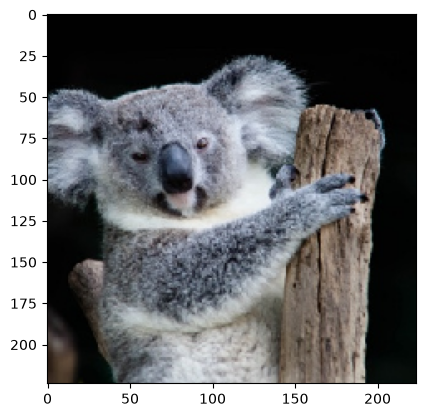

1/1 [==============================] - 0s 99ms/step
Target image class label: 866 (tractor)


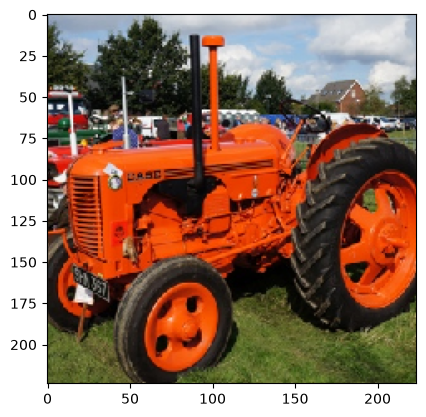

In [5]:
init_class_id = np.argmax(model.predict(np.array([init_image])))
print(f"Init image class label: {init_class_id} ({class_lookup[init_class_id]})")
plt.imshow(init_image.astype(np.uint))
plt.show()

target_class_id = np.argmax(model.predict(np.array([target_image])))
print(f"Target image class label: {target_class_id} ({class_lookup[target_class_id]})")
plt.imshow(target_image.astype(np.uint))
plt.show()

## Implementation av er attack

Beskriv i er rapport vad just er valda attack kallas och i detalj hur den fungerar (sektion 2.2 i rapporten). Beskriv även kort vilka bibliotek ni använder för att implementera den.

## Er kod för attacken

I cellerna nedan lägger ni in er egen kod för att genomföra attacken.

### Bibliotek

In [6]:
# Samla era import statements här e.g.
# import matplotlib.pyplot as plt
# import numpy as np
# import pandas as pd
# ...
from art.attacks.evasion import ProjectedGradientDescent
from art.estimators.classification import TensorFlowV2Classifier


### Egna funktioner

In [22]:
# # Gör om rgb-bilder till bgr eftersom ResNet50 är tränat på bilder där pixlarna är på den formen.
class convert_to_bgr(tf.keras.Model):
    def __init__(self, base):
        super().__init__()
        self.base = base

    def call(self, x, training=False):
        x = preprocess_input(x)
        return self.base(x, training=training)

converted_model = convert_to_bgr(model)



# Grad-CAM for ResNet50
def grad_cam(img, class_id=None):

    grad_model = tf.keras.Model(
        inputs=model.inputs,
        outputs=[
            model.get_layer("conv5_block3_out").output,
            model.output
        ]
    )

    # Same preprocessing as your ART wrapper
    img_tensor = tf.convert_to_tensor(img.copy(), dtype=tf.float32)
    img_processed = preprocess_input(img_tensor)

    with tf.GradientTape() as tape:

        conv_output, predictions = grad_model(
            img_processed, training=False
        )

        if class_id is None:
            class_id = tf.argmax(predictions[0])

        class_score = predictions[:, class_id]

    # Gradient of selected class w.r.t. feature maps
    grads = tape.gradient(class_score, conv_output)

    # Average gradients over spatial dimensions
    weights = tf.reduce_mean(grads, axis=(1, 2))

    # Weighted combination of feature maps
    heatmap = tf.reduce_sum(
        conv_output[0] * weights[0],
        axis=-1
    )

    heatmap = tf.maximum(heatmap, 0)

    # Normalize to [0, 1]
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)

    # Resize to original image dimensions
    heatmap = tf.image.resize(
        heatmap[..., tf.newaxis],
        (224, 224)
    )

    return heatmap.numpy().squeeze()

### Förberedelser

In [8]:
print(model.output_shape)
print(model.input_shape)
print(init_image.min(), init_image.max())
# print(target.shape)

(None, 1000)
(None, 224, 224, 3)
0.0 249.0


In [9]:
classifier = TensorFlowV2Classifier(
    model=converted_model,
    nb_classes=1000,
    input_shape=(224, 224, 3),
    loss_object=keras.losses.CategoricalCrossentropy(from_logits=False),
    clip_values=(0, 255),
)


### Modellering

In [10]:
# E.g. träning

pgd_attack = ProjectedGradientDescent(
    estimator=classifier,
    eps=8,
    verbose=True,
    targeted=True,
)

### Attack

Beskriv attackprocessen kortfattat här

In [11]:
# Koalabilden med batch-dimension: (1, 224, 224, 3)
x = np.expand_dims(init_image, axis=0).astype(np.float32)

# Målklassen traktor som one-hot-vektor
target = to_categorical([target_class_id], nb_classes=1000)

adv_image = pgd_attack.generate(
    x=x,
    y=target
)


### Attackresultat

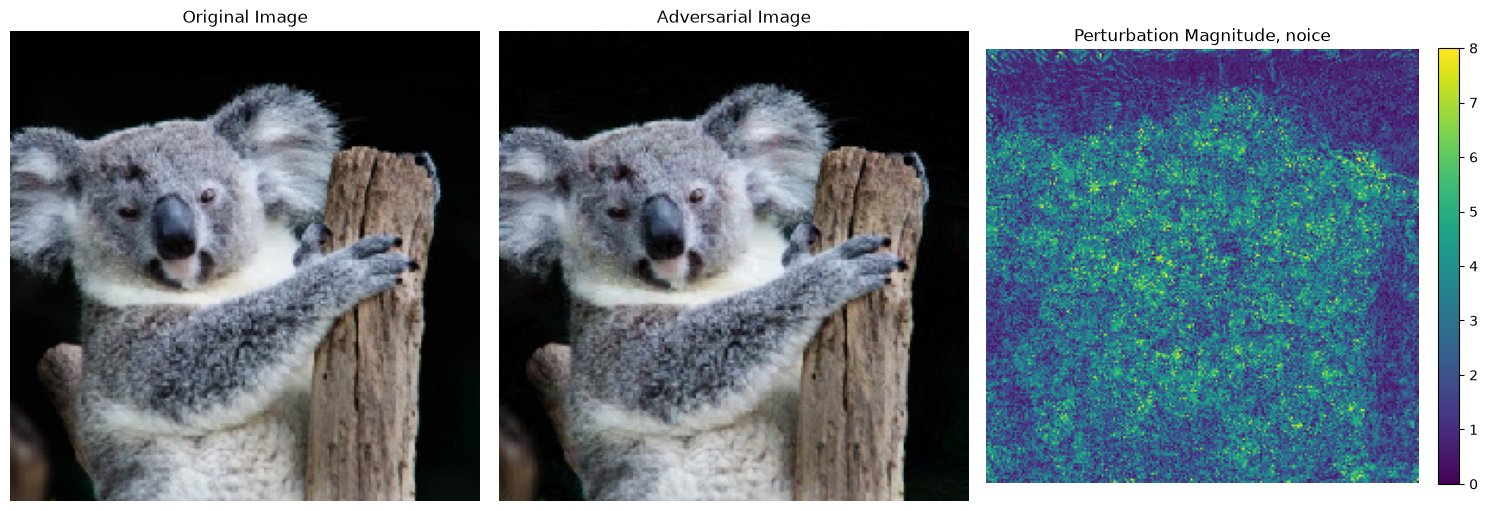

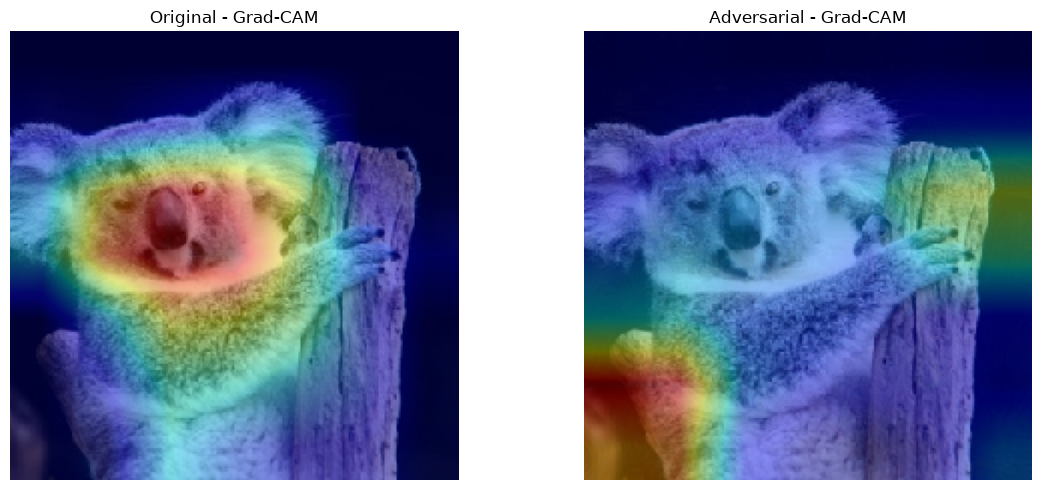

In [ ]:

# Presentera attackens resultat

fig, ax = plt.subplots(1, 3, figsize=(15, 5))

# Calculate perturbation
diff = adv_image[0] - x[0]

# Calculate absolute perturbation magnitude
diff_magnitude = np.max(np.abs(diff), axis=-1)

# Original image
ax[0].imshow(init_image.astype(np.uint8))
ax[0].set_title("Original Image")
ax[0].axis("off")

# Adversarial image
ax[1].imshow(np.clip(adv_image[0], 0, 255).astype(np.uint8))
ax[1].set_title("Adversarial Image")
ax[1].axis("off")

# Perturbation (enhanced visualization)
im = ax[2].imshow(diff_magnitude) #, cmap="inferno")
ax[2].set_title("Perturbation Magnitude, noice")
ax[2].axis("off")

fig.colorbar(im, ax=ax[2], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()




# Generate Grad-CAM for both images
cam_original = grad_cam(x)
cam_adversarial = grad_cam(adv_image)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# Original image
ax[0].imshow(x[0].astype(np.uint8))
ax[0].imshow(cam_original, cmap="jet", alpha=0.4,
             vmin=0, vmax=1)
ax[0].set_title("Original - Grad-CAM")

# Adversarial image
ax[1].imshow(np.clip(adv_image[0], 0, 255).astype(np.uint8))
ax[1].imshow(cam_adversarial, cmap="jet", alpha=0.4,
             vmin=0, vmax=1)
ax[1].set_title("Adversarial - Grad-CAM")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()




## Skyddsåtgärder

Beskriv (i rapportens sektion 2.3) vilka säkerhetsåtgärd(er) ni valt som lämpliga för att skydda mot er attack. Motivera varför ni valt just de(n) metod(erna).

## Implementation av skyddsåtgärder (frivilligt endast för A eller B)

Nedan fyller ni i er kod som implementerar skyddsmekanismen mot er attackmetod. Skriv även en summering av vad skyddsresultatet blev när ni implementerade metoden (beskriv detta i rapportens del 2.4).

### Egna funktioner

In [13]:
# Samla era egna funktioner relaterade till säkerhetsåtgärden här
# Funktionerna ska kort beskrivas med docstrings och kommentarer så att man förstår syftet och implementationen
# Blir det många bör ni bryta ut dessa i en separat fil




### Förberedelser

In [14]:
# E.g. skapande av ny modell, etc.

### Skydd

Beskriv säkerhetsåtgärden kortfattat här

In [15]:
# Implementation av skyddsåtgärd

### Skyddsresultat

Bevisa och förklara era skyddsresultat i flytande text här

In [16]:
# Presentera skyddåtgärdens resultat m.h.a. kod här

# Referenser

Lista era referenser här. E.g. var ni hittat information om attacken, skyddsåtgärder eller bibliotekets dokumentation/repository.